In [2]:
%pip install --only-binary=:all: "sentence-transformers>=3.4,<6" "transformers>=4.41,<5" "ipywidgets>=8,<9"
print("Installation finished. Importing libraries...")
import os, random, json, re, io, hashlib, shutil, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, precision_recall_curve, average_precision_score,
    roc_auc_score, auc, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import copy
from scipy.sparse import hstack
import joblib
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ROOT = Path('/content/inclusive_ats_pytorch'); ROOT.mkdir(exist_ok=True)
print('Device:', 'cuda' if torch.cuda.is_available() else 'cpu')


Installation finished. Importing libraries...
Device: cpu


In [3]:
MODULE = "import hashlib\nimport json\nimport re\nfrom pathlib import Path\n\nimport joblib\nimport numpy as np\nimport torch\nfrom torch import nn\nfrom sentence_transformers import SentenceTransformer\nfrom tqdm.auto import tqdm\n\nSKILLS = {skill: [skill] for skill in [\n    'python', 'java', 'c++', 'c#', '.net', 'sql', 'mysql', 'postgresql',\n    'mongodb', 'javascript', 'typescript', 'react', 'angular', 'html', 'css',\n    'docker', 'kubernetes', 'git', 'linux', 'aws', 'azure', 'tensorflow',\n    'pytorch', 'pandas', 'numpy', 'excel', 'tableau', 'power bi', 'accounting',\n    'budgeting', 'recruitment', 'payroll', 'sales', 'marketing', 'communication',\n    'project management', 'machine learning', 'data analysis', 'customer service'\n]}\nSKILLS.update({\n    'node.js': ['node.js', 'nodejs', 'node js'],\n    'express': ['express.js', 'expressjs'],\n    'rest api': ['rest api', 'restful api', 'rest apis'],\n    'scikit-learn': ['scikit-learn', 'sklearn'],\n    'aws': ['aws', 'amazon web services'],\n})\n\n\ndef clean(text, mask=True):\n    if not isinstance(text, str) or not text.strip():\n        raise ValueError('Résumé and job text must both be nonempty strings.')\n    text = text.replace('\\r\\n', '\\n').replace('\\r', '\\n')\n    if mask:\n        text = re.sub(r'(?im)^\\s*(?:name|candidate name|full name)\\s*:[^\\n]*', 'PERSON', text)\n        text = re.sub(r'(?i)\\b(?:age\\s*[:=]?\\s*\\d{1,3}|\\d{1,3}\\s*(?:years? old|year-old))\\b', 'PERSONAL_DETAIL', text)\n        text = re.sub(r'(?im)\\b(?:date of birth|dob)\\s*:[^\\n,;]*', 'PERSONAL_DETAIL', text)\n        text = re.sub(r'(?im)^\\s*pronouns\\s*:[^\\n]*', 'PERSON', text)\n        text = re.sub(r'(?i)\\b[\\w.+-]+@[\\w.-]+\\.[a-z]{2,}\\b', 'CONTACT', text)\n        text = re.sub(r'(?i)https?://\\S+|www\\.\\S+', 'CONTACT', text)\n        # At least 10 digits avoids masking ordinary year ranges such as 2019-2024.\n        text = re.sub(r'(?<!\\w)\\+?\\d[\\d ()-]{7,}\\d(?!\\w)',\n                      lambda m: 'CONTACT' if len(re.sub(r'\\D', '', m[0])) >= 10 else m[0], text)\n        text = re.sub(r'(?i)\\b(?:he|she|him|her|his|hers|they|them|their|theirs)\\b', 'PERSON', text)\n        lines = text.splitlines()\n        if lines and re.fullmatch(r'[A-Z][a-z]+(?: [A-Z][a-z]+){1,3}', lines[0].strip()):\n            if not re.search(r'Engineer|Developer|Manager|Analyst|Resume|Curriculum|Vitae|Skills|Experience', lines[0]):\n                lines[0] = 'PERSON'\n        text = '\\n'.join(lines)\n    return re.sub(r'\\s+', ' ', text).strip()\n\n\ndef skills(text, vocabulary=None):\n    vocabulary = SKILLS if vocabulary is None else vocabulary\n    text = text.lower()\n    return {skill for skill, aliases in vocabulary.items()\n            if any(re.search(r'(?<![\\w+#.])' + re.escape(alias) + r'(?![\\w+#])', text)\n                   for alias in aliases)}\n\n\ndef skill_result(resume, job, vocabulary=None):\n    required = skills(job, vocabulary)\n    present = skills(resume, vocabulary)\n    matched = sorted(required & present)\n    missing = sorted(required - present)\n    coverage = len(matched) / len(required) if required else 0.0\n    return matched, missing, coverage\n\n\nclass Features:\n    def __init__(self, model='sentence-transformers/all-MiniLM-L6-v2', cache=None,\n                 vocabulary=None, device=None, batch_size=32, chunk_tokens=240):\n        self.encoder = SentenceTransformer(str(model), device=device)\n        self.encoder.eval()\n        self.vocabulary = SKILLS if vocabulary is None else vocabulary\n        self.batch_size = batch_size\n        self.chunk_tokens = min(chunk_tokens, self.encoder.max_seq_length -\n                                self.encoder.tokenizer.num_special_tokens_to_add(pair=False))\n        self.cache = Path(cache) if cache else None\n        if self.cache:\n            self.cache.mkdir(parents=True, exist_ok=True)\n        # Fingerprint weights so a changed encoder never reuses old embeddings.\n        digest = hashlib.sha256()\n        digest.update(self.encoder.tokenizer.backend_tokenizer.to_str().encode())\n        digest.update(f'ats-v2|{self.chunk_tokens}|weighted-normalized'.encode())\n        for name, tensor in self.encoder.state_dict().items():\n            digest.update(name.encode())\n            digest.update(tensor.detach().cpu().contiguous().numpy().tobytes())\n        self.signature = digest.hexdigest()\n\n    def encode(self, texts):\n        unique = list(dict.fromkeys(texts))\n        vectors = {}\n        pending = []\n        paths = {}\n        for text in unique:\n            key = hashlib.sha256((self.signature + text).encode()).hexdigest()\n            path = self.cache / (key + '.npy') if self.cache else None\n            paths[text] = path\n            if path and path.exists():\n                vector = np.load(path, allow_pickle=False)\n                if vector.shape != (384,) or not np.isfinite(vector).all():\n                    raise ValueError(f'Invalid embedding cache file. Remove {path} and rerun.')\n                vectors[text] = vector\n            else:\n                pending.append(text)\n        if pending:\n            sums = np.zeros((len(pending), 384), dtype=np.float64)\n            weights = np.zeros(len(pending), dtype=np.float64)\n            batch, owners, sizes = [], [], []\n            tokenizer = self.encoder.tokenizer\n\n            def flush():\n                tokens = tokenizer.pad(batch, padding=True, return_tensors='pt')\n                tokens = {key: value.to(self.encoder.device) for key, value in tokens.items()}\n                with torch.inference_mode():\n                    output = self.encoder(tokens)['sentence_embedding']\n                    output = torch.nn.functional.normalize(output, p=2, dim=1).cpu().numpy()\n                for vector, owner, size in zip(output, owners, sizes):\n                    sums[owner] += vector * size\n                    weights[owner] += size\n                batch.clear()\n                owners.clear()\n                sizes.clear()\n\n            for owner, text in enumerate(tqdm(pending, desc='Encoding unique texts')):\n                ids = tokenizer.encode(text, add_special_tokens=False, truncation=False)\n                for start in range(0, max(1, len(ids)), self.chunk_tokens):\n                    chunk = ids[start:start + self.chunk_tokens]\n                    encoded = tokenizer.prepare_for_model(chunk, add_special_tokens=True,\n                                                          truncation=False, return_attention_mask=True)\n                    batch.append(encoded)\n                    owners.append(owner)\n                    sizes.append(max(1, len(chunk)))\n                    if len(batch) == self.batch_size:\n                        flush()\n            if batch:\n                flush()\n            for owner, text in enumerate(pending):\n                vector = sums[owner] / weights[owner]\n                vector = (vector / max(np.linalg.norm(vector), 1e-12)).astype(np.float32)\n                vectors[text] = vector\n                if paths[text]:\n                    temporary = paths[text].with_suffix('.tmp')\n                    with temporary.open('wb') as handle:\n                        np.save(handle, vector)\n                    temporary.replace(paths[text])\n        return np.stack([vectors[text] for text in texts])\n\n    def build(self, resumes, jobs, mask=True):\n        if len(resumes) != len(jobs) or len(resumes) == 0:\n            raise ValueError('Provide equally sized, nonempty résumé and job lists.')\n        resumes = [clean(text, mask) for text in resumes]\n        jobs = [clean(text, mask) for text in jobs]\n        joined = self.encode(resumes + jobs)\n        a, b = joined[:len(resumes)], joined[len(resumes):]\n        coverage = np.array([skill_result(r, j, self.vocabulary)[2]\n                             for r, j in zip(resumes, jobs)], dtype=np.float32)[:, None]\n        matrix = np.concatenate([(a * b).sum(axis=1, keepdims=True),\n                                 np.abs(a - b), a * b, coverage], axis=1).astype(np.float32)\n        if matrix.shape != (len(resumes), 770) or not np.isfinite(matrix).all():\n            raise ValueError('Pair features must have 770 finite values per example.')\n        return matrix\n\n\nclass MatchNetwork(nn.Module):\n    def __init__(self):\n        super().__init__()\n        self.layers = nn.Sequential(\n            nn.Linear(770, 256), nn.ReLU(), nn.Dropout(0.3),\n            nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.2), nn.Linear(64, 1))\n\n    def forward(self, matrix):\n        return self.layers(matrix).squeeze(-1)\n\n\ndef probabilities(model, scaler, matrix, device='cpu', batch_size=1024):\n    matrix = scaler.transform(matrix).astype(np.float32)\n    model.eval()\n    output = []\n    with torch.inference_mode():\n        for start in range(0, len(matrix), batch_size):\n            batch = torch.from_numpy(matrix[start:start + batch_size]).to(device)\n            output.append(torch.sigmoid(model(batch)).cpu().numpy())\n    return np.concatenate(output)\n\n\ndef predict(features, model, scaler, threshold, resume, job, device='cpu', mask=True):\n    matrix = features.build([resume], [job], mask=mask)\n    probability = float(probabilities(model, scaler, matrix, device)[0])\n    matched, missing, coverage = skill_result(clean(resume, mask), clean(job, mask), features.vocabulary)\n    return {\n        'score': 100 * probability,\n        'prediction': 'strong match' if probability >= threshold else 'weaker match',\n        'semantic_similarity': float(matrix[0, 0]),\n        'required_skill_coverage': coverage if matched or missing else None,\n        'matched_skills': matched, 'missing_skills': missing,\n        'recognized_job_skills': len(matched) + len(missing),\n    }\n\n\nclass Predictor:\n    def __init__(self, path, device='cpu'):\n        path = Path(path)\n        self.config = json.loads((path / 'settings.json').read_text())\n        self.device = device\n        self.features = Features(path / 'encoder', device=device,\n                                 vocabulary=json.loads((path / 'skills.json').read_text()),\n                                 chunk_tokens=self.config['chunk_tokens'])\n        self.scaler = joblib.load(path / 'scaler.joblib')\n        self.model = MatchNetwork().to(device)\n        self.model.load_state_dict(torch.load(path / 'classifier.pt', map_location=device, weights_only=True))\n        self.model.eval()\n\n    def predict(self, resume, job):\n        return predict(self.features, self.model, self.scaler, self.config['threshold'],\n                       resume, job, self.device)\n"
(ROOT/'ats_core.py').write_text(MODULE)
import sys, importlib
sys.path.insert(0, str(ROOT))
sys.modules.pop('ats_core', None)
from ats_core import (clean, skills, skill_result, Features, MatchNetwork,
                      probabilities, predict, Predictor, SKILLS)


In [4]:
def load_tables(folder='/content'):
    folder = Path(folder)
    specifications = {
        'cv.csv': ['candidate_id', 'resume_text'],
        'job.csv': ['job_id', 'job_description'],
        'matches.csv': ['candidate_id', 'job_id', 'label_strength'],
    }
    paths = {}
    for filename in specifications:
        exact = folder / filename
        candidates = sorted(folder.glob(Path(filename).stem + '*.csv'))
        if exact.exists():
            paths[filename] = exact
        elif len(candidates) == 1:
            paths[filename] = candidates[0]
        else:
            raise FileNotFoundError(
                f'Expected {filename} in {folder}. Found {len(candidates)} possible files. '
                'Upload all three CSVs or rename the correct file to its expected name.')
    tables = []
    for filename, required in specifications.items():
        path = paths[filename]
        columns = pd.read_csv(path, nrows=0).columns.tolist()
        print(f'{path.name}: {columns}')
        normalized = {column.strip(): column for column in columns}
        if len(normalized) != len(columns):
            raise ValueError(f'{filename} has ambiguous columns after trimming whitespace.')
        missing = set(required) - normalized.keys()
        if missing:
            raise ValueError(f'{filename} is missing required columns: {sorted(missing)}')
        table = pd.read_csv(path, usecols=[normalized[name] for name in required],
                            dtype=str, keep_default_na=False)
        table.columns = table.columns.str.strip()
        tables.append(table[required].copy())
        print('Loaded shape:', table.shape)
    return tuple(tables)


In [5]:
from google.colab import files
uploaded = files.upload()

Saving cv (1).csv to cv (1) (1).csv
Saving job (1).csv to job (1) (1).csv
Saving matches (1).csv to matches (1) (1).csv


In [7]:
import pandas as pd

cv = pd.read_csv(
    "/content/cv (1) (1).csv",
    usecols=["candidate_id", "resume_text"],
    dtype=str,
    keep_default_na=False
)

jobs = pd.read_csv(
    "/content/job (1) (1).csv",
    usecols=["job_id", "job_description"],
    dtype=str,
    keep_default_na=False
)

matches = pd.read_csv(
    "/content/matches (1) (1).csv",
    usecols=["candidate_id", "job_id", "label_strength"],
    dtype=str,
    keep_default_na=False
)

print("Dataset loading completed.")
print(f"Résumés: {len(cv):,}")
print(f"Jobs:    {len(jobs):,}")
print(f"Matches: {len(matches):,}")

Dataset loading completed.
Résumés: 9,544
Jobs:    1,167
Matches: 122,560


,count
label_strength,
medium_positive,70636
weak_positive,51150
strong_positive,774


cv empty cells {'candidate_id': 0, 'resume_text': 0}
jobs empty cells {'job_id': 0, 'job_description': 0}
matches empty cells {'candidate_id': 0, 'job_id': 0, 'label_strength': 0}


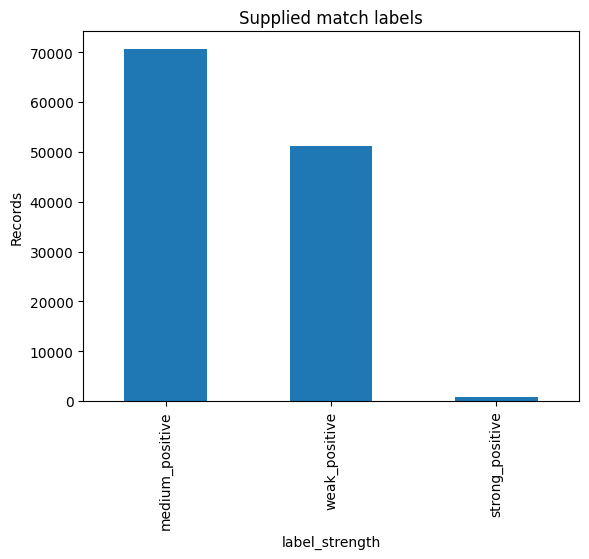

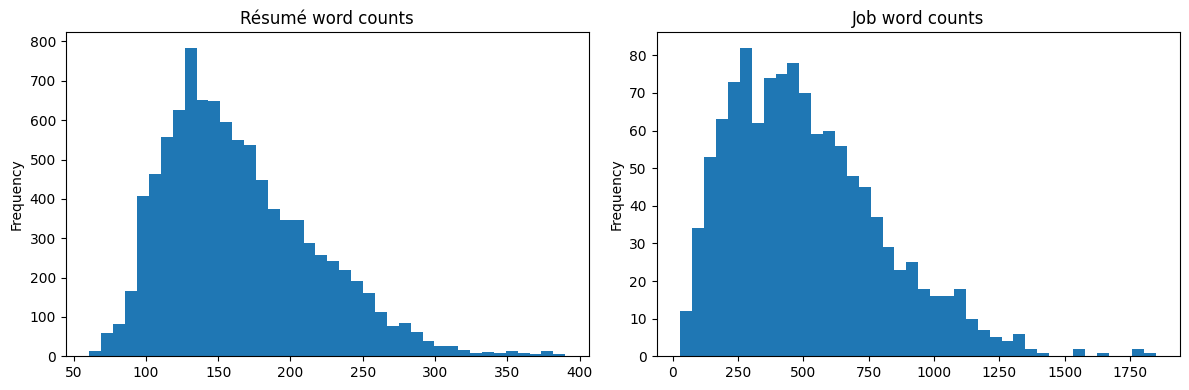

In [8]:
display(matches.label_strength.value_counts().to_frame('count'))
for name, table in [('cv',cv),('jobs',jobs),('matches',matches)]:
    print(name, 'empty cells', table.eq('').sum().to_dict())
matches.label_strength.value_counts().plot.bar(title='Supplied match labels'); plt.ylabel('Records'); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cv.resume_text.str.split().str.len().plot.hist(bins=40, ax=axes[0], title='Résumé word counts')
jobs.job_description.str.split().str.len().plot.hist(bins=40, ax=axes[1], title='Job word counts')
plt.tight_layout(); plt.show()

In [9]:
def normalize_id(s):
    return s.str.strip().str.replace(r'^(\d+)\.0+$',r'\1',regex=True)
def unique_records(table, keys, values):
    table=table[keys+values].copy()
    for k in keys: table[k]=normalize_id(table[k])
    before=len(table)
    table=table.loc[table[keys+values].apply(lambda s:s.str.strip().ne('')).all(axis=1)]
    print('Removed missing records:',before-len(table))
    for v in values:
        if table.groupby(keys)[v].nunique().gt(1).any():
            raise ValueError(f'Conflicting duplicate IDs/pairs for {keys}, column {v}. Resolve source conflicts first.')
    before=len(table); table=table.drop_duplicates(keys)
    print('Collapsed repeated keys:',before-len(table))
    return table
expected={'strong_positive','medium_positive','weak_positive'}
matches['label_strength']=matches.label_strength.str.strip()
if set(matches.label_strength)!=expected:
    raise ValueError(f'Expected exactly {expected}; found {set(matches.label_strength)}. Target definition requires review.')
cv=unique_records(cv,['candidate_id'],['resume_text'])
jobs=unique_records(jobs,['job_id'],['job_description'])
matches=unique_records(matches,['candidate_id','job_id'],['label_strength'])


Removed missing records: 0
Collapsed repeated keys: 0
Removed missing records: 0
Collapsed repeated keys: 0
Removed missing records: 0
Collapsed repeated keys: 0


In [10]:
candidate_missing = ~matches.candidate_id.isin(cv.candidate_id)
job_missing = ~matches.job_id.isin(jobs.job_id)
join_report = {'unmatched_candidate_records': int(candidate_missing.sum()),
               'unmatched_job_records': int(job_missing.sum()),
               'excluded_records': int((candidate_missing | job_missing).sum())}
print(join_report)
data = matches.loc[~candidate_missing & ~job_missing].merge(
    cv, on='candidate_id', validate='many_to_one').merge(
    jobs, on='job_id', validate='many_to_one')
data['target'] = data.label_strength.eq('strong_positive').astype(int)
assert len(data) > 0 and not data.duplicated(['candidate_id', 'job_id']).any()
assert len(data) == len(matches) - join_report['excluded_records']
print('Integrated rows:', len(data))
print('All-weaker accuracy reference:', 1 - data.target.mean())


{'unmatched_candidate_records': 0, 'unmatched_job_records': 0, 'excluded_records': 0}
Integrated rows: 122560
All-weaker accuracy reference: 0.9936847258485639


In [11]:
data['group']=data.resume_text.map(lambda t:hashlib.sha256(clean(t).lower().encode()).hexdigest())
split=GroupShuffleSplit(n_splits=1,train_size=.70,random_state=SEED)
tr,rest=next(split.split(data,groups=data.group))
sub=data.iloc[rest]
va,te=next(GroupShuffleSplit(n_splits=1,train_size=.5,random_state=SEED).split(sub,groups=sub.group))
parts={'train':data.iloc[tr].copy(),'validation':sub.iloc[va].copy(),'test':sub.iloc[te].copy()}
for name,part in parts.items():
    assert part.target.nunique()==2, f'{name} lacks a class; acquire more diverse labeled candidates.'
    print(name,len(part),part.target.value_counts().to_dict())
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    for key in ['candidate_id','group']:
        assert not set(parts[a][key]) & set(parts[b][key])


train 85590 {0: 85079, 1: 511}
validation 18437 {0: 18297, 1: 140}
test 18533 {0: 18410, 1: 123}


In [12]:
assert all(t.lower() in clean('C++ C# .NET Node.js').lower() for t in ['C++','C#','.NET','Node.js'])
assert '5 years' in clean('Experience: 5 years in Python')
for part in parts.values():
    part['r']=part.resume_text.map(clean); part['j']=part.job_description.map(clean)
assert skills('C++, C#, .NET and Node.js') >= {'c++', 'c#', '.net', 'node.js'}
assert '2019-2024' in clean('Employment: 2019-2024')
assert clean('Name: Alex Morgan\nAge: 25\nPython, 5 years experience') == clean(
    'Name: Priya Sen\nAge: 55\nPython, 5 years experience')
try:
    clean('   ')
except ValueError:
    print('Empty-input validation passed.')
else:
    raise AssertionError('Empty text must be rejected.')


Empty-input validation passed.


In [14]:
import time

started = time.perf_counter()
print("Step 1: Preparing encoder...", flush=True)

if "features" not in globals():
    features = Features(
        cache=ROOT / "embedding_cache",
        device=DEVICE,
        batch_size=32 if DEVICE == "cuda" else 16
    )

print(
    f"Encoder ready after {time.perf_counter() - started:.1f} seconds.",
    flush=True
)

if "X" not in globals():
    X = {}

y = {
    name: part.target.to_numpy()
    for name, part in parts.items()
}

for name in ["train", "validation"]:
    if name in X:
        print(f"{name}: using completed features {X[name].shape}", flush=True)
        continue

    part = parts[name]
    step_started = time.perf_counter()
    print(f"Step 2: Building {name} features...", flush=True)

    X[name] = features.build(
        part.resume_text.tolist(),
        part.job_description.tolist()
    )

    print(
        f"{name}: finished in "
        f"{(time.perf_counter() - step_started) / 60:.1f} minutes. "
        f"Shape: {X[name].shape}",
        flush=True
    )

print("Feature extraction completed.", flush=True)

Step 1: Preparing encoder...
Encoder ready after 0.0 seconds.
train: using completed features (85590, 770)
Step 2: Building validation features...


Encoding unique texts:   0%|          | 0/1432 [00:00<?, ?it/s]

validation: finished in 7.2 minutes. Shape: (18437, 770)
Feature extraction completed.


In [15]:
import time
import numpy as np
import pandas as pd
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer

started = time.perf_counter()

training_texts = pd.concat(
    [parts["train"]["r"], parts["train"]["j"]],
    ignore_index=True
).drop_duplicates()

print(
    f"Fitting TF-IDF on {len(training_texts):,} unique training texts...",
    flush=True
)

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    token_pattern=r"(?u)(?<!\w)[\w.+#-]+",
    dtype=np.float32
)
tfidf.fit(training_texts)

print("Vocabulary fitted.", flush=True)

B = {}

for name in ["train", "validation"]:
    part = parts[name]
    pair_count = len(part)

    combined = pd.concat(
        [part["r"], part["j"]],
        ignore_index=True
    )

    codes, unique_texts = pd.factorize(combined, sort=False)

    print(
        f"{name}: transforming {len(unique_texts):,} unique texts...",
        flush=True
    )

    unique_vectors = tfidf.transform(unique_texts)

    resume_vectors = unique_vectors[codes[:pair_count]]
    job_vectors = unique_vectors[codes[pair_count:]]

    B[name] = hstack(
        [
            resume_vectors,
            job_vectors,
            resume_vectors.multiply(job_vectors)
        ],
        format="csr"
    )

    print(f"{name}: completed {B[name].shape}", flush=True)

print(
    f"TF-IDF completed in {(time.perf_counter() - started) / 60:.1f} minutes.",
    flush=True
)

Fitting TF-IDF on 7,833 unique training texts...
Vocabulary fitted.
train: transforming 7,833 unique texts...
train: completed (85590, 60000)
validation: transforming 2,470 unique texts...
validation: completed (18437, 60000)
TF-IDF completed in 0.3 minutes.


In [16]:
def choose_threshold(y,p):
    precision,recall,thresholds=precision_recall_curve(y,p)
    precision=precision[:-1]; recall=recall[:-1]
    f1=2*precision*recall/np.maximum(precision+recall,1e-12)
    feasible=(precision>=.94)&(recall>=.91)
    options=np.where(feasible)[0] if feasible.any() else np.arange(len(thresholds))
    index=max(options,key=lambda i:(f1[i],precision[i],thresholds[i]))
    return float(thresholds[index]),bool(feasible.any()),float(f1[index]),float(precision[index])
def train_search(matrices):
    trials=[]; best=None
    for C in [.1,1.,10.]:
        model=LogisticRegression(C=C,class_weight='balanced',max_iter=2000,random_state=SEED,solver='liblinear')
        model.fit(matrices['train'],y['train'])
        threshold,feasible,f1,precision=choose_threshold(y['validation'],model.predict_proba(matrices['validation'])[:,1])
        trials.append(dict(C=C,threshold=threshold,precision_recall_goals_met=feasible,F1=f1,precision=precision))
        rank=(feasible,f1,precision)
        if best is None or rank>best[0]: best=(rank,model,threshold)
    display(pd.DataFrame(trials))
    return best[1],best[2],trials
baseline,baseline_threshold,baseline_trials=train_search(B)


,C,threshold,precision_recall_goals_met,F1,precision
0,0.1,0.908829,False,0.364103,0.284000
1,1.0,0.937309,False,0.325056,0.237624
2,10.0,0.939315,False,0.305221,0.212291


LR=0.001 epoch=01 loss=1.8478 validation AP=0.2705
LR=0.001 epoch=02 loss=1.3206 validation AP=0.3746
LR=0.001 epoch=03 loss=0.9697 validation AP=0.3641
LR=0.001 epoch=04 loss=0.7566 validation AP=0.4193
LR=0.001 epoch=05 loss=0.7058 validation AP=0.3790
LR=0.001 epoch=06 loss=0.6123 validation AP=0.4334
LR=0.001 epoch=07 loss=0.5758 validation AP=0.4529
LR=0.001 epoch=08 loss=0.5661 validation AP=0.4127
LR=0.001 epoch=09 loss=0.4964 validation AP=0.4006
LR=0.001 epoch=10 loss=0.3613 validation AP=0.4381
LR=0.001 epoch=11 loss=0.4625 validation AP=0.3899
LR=0.001 epoch=12 loss=0.3795 validation AP=0.3676
LR=0.0003 epoch=01 loss=1.6917 validation AP=0.3297
LR=0.0003 epoch=02 loss=1.2681 validation AP=0.3681
LR=0.0003 epoch=03 loss=1.0004 validation AP=0.3693
LR=0.0003 epoch=04 loss=0.7747 validation AP=0.4394
LR=0.0003 epoch=05 loss=0.6906 validation AP=0.3566
LR=0.0003 epoch=06 loss=0.5334 validation AP=0.4355
LR=0.0003 epoch=07 loss=0.5092 validation AP=0.4361
LR=0.0003 epoch=08 loss=

,learning_rate,best_epoch,validation_AP,threshold,precision_recall_goals_met,f1,precision,recall
0,0.0010,7,0.452889,0.903234,False,0.494545,0.503704,0.485714
1,0.0003,9,0.441287,0.205804,False,0.486486,0.419689,0.578571


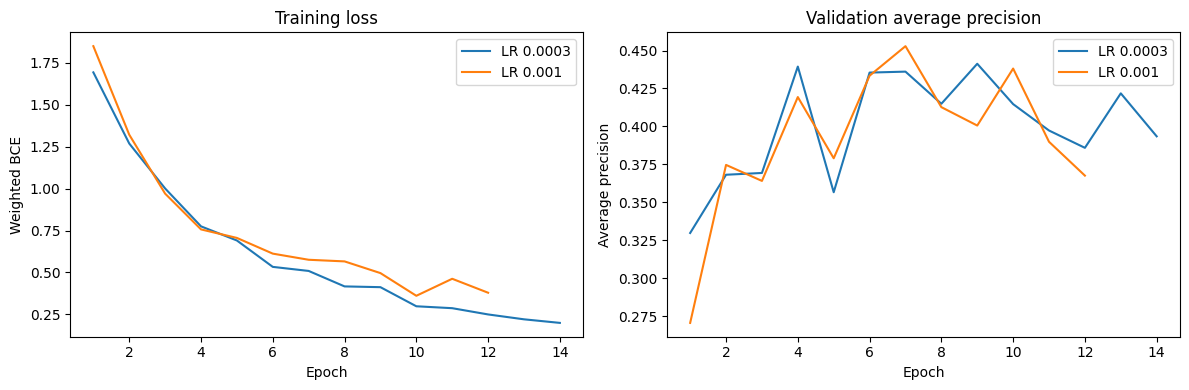

In [17]:
scaler = StandardScaler().fit(X['train'])
train_tensor = torch.from_numpy(scaler.transform(X['train']).astype(np.float32))
target_tensor = torch.from_numpy(y['train'].astype(np.float32))
positive_count = int(y['train'].sum())
positive_weight = float((len(y['train']) - positive_count) / positive_count)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))
training_history = []
neural_trials = []
selected = None
for learning_rate in [0.001, 0.0003]:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    model = MatchNetwork().to(DEVICE)
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TensorDataset(train_tensor, target_tensor), batch_size=64,
                        shuffle=True, generator=generator, num_workers=0)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    best_ap, stale, checkpoint, best_epoch = -1.0, 0, None, 0
    for epoch in range(1, 31):
        model.train()
        total_loss = 0.0
        for batch, targets in loader:
            batch, targets = batch.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(batch), targets)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite training loss. Inspect features and class counts.')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += float(loss.detach()) * len(batch)
        validation_p = probabilities(model, scaler, X['validation'], DEVICE)
        validation_ap = average_precision_score(y['validation'], validation_p)
        training_history.append({'learning_rate': learning_rate, 'epoch': epoch,
                                 'train_loss': total_loss / len(train_tensor),
                                 'validation_average_precision': float(validation_ap)})
        print(f'LR={learning_rate} epoch={epoch:02d} loss={total_loss / len(train_tensor):.4f} '
              f'validation AP={validation_ap:.4f}')
        if validation_ap > best_ap + 1e-6:
            best_ap, stale, best_epoch = validation_ap, 0, epoch
            checkpoint = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale += 1
        if stale >= 5:
            break
    model.load_state_dict(checkpoint)
    validation_p = probabilities(model, scaler, X['validation'], DEVICE)
    trial_threshold, feasible, trial_f1, trial_precision = choose_threshold(y['validation'], validation_p)
    trial_recall = recall_score(y['validation'], validation_p >= trial_threshold)
    neural_trials.append({'learning_rate': learning_rate, 'best_epoch': best_epoch,
                         'validation_AP': float(best_ap), 'threshold': trial_threshold,
                         'precision_recall_goals_met': feasible, 'f1': trial_f1,
                         'precision': trial_precision, 'recall': float(trial_recall)})
    rank = (feasible, trial_f1, trial_precision)
    if selected is None or rank > selected['rank']:
        selected = {'rank': rank, 'state': checkpoint, 'threshold': trial_threshold,
                    'learning_rate': learning_rate, 'best_epoch': best_epoch}
classifier = MatchNetwork().to(DEVICE)
classifier.load_state_dict(selected['state'])
classifier.eval()
threshold = selected['threshold']
display(pd.DataFrame(neural_trials))
history = pd.DataFrame(training_history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for learning_rate, group in history.groupby('learning_rate'):
    axes[0].plot(group.epoch, group.train_loss, label=f'LR {learning_rate}')
    axes[1].plot(group.epoch, group.validation_average_precision, label=f'LR {learning_rate}')
axes[0].set(title='Training loss', xlabel='Epoch', ylabel='Weighted BCE')
axes[1].set(title='Validation average precision', xlabel='Epoch', ylabel='Average precision')
for axis in axes:
    axis.legend()
plt.tight_layout(); plt.show()


In [18]:
print('Frozen threshold:', threshold)
print('Selected learning rate:', selected['learning_rate'])
print('Best epoch:', selected['best_epoch'])
print('Validation precision/recall targets met:', selected['rank'][0])

Frozen threshold: 0.9032344818115234
Selected learning rate: 0.001
Best epoch: 7
Validation precision/recall targets met: False


Encoding unique texts:   0%|          | 0/1431 [00:00<?, ?it/s]

,precision,recall,f1-score,support
weaker,0.996821,0.987887,0.992334,18410.000000
strong,0.225694,0.528455,0.316302,123.000000
accuracy,0.984838,0.984838,0.984838,0.984838
macro avg,0.611258,0.758171,0.654318,18533.000000
weighted avg,0.991703,0.984838,0.987847,18533.000000


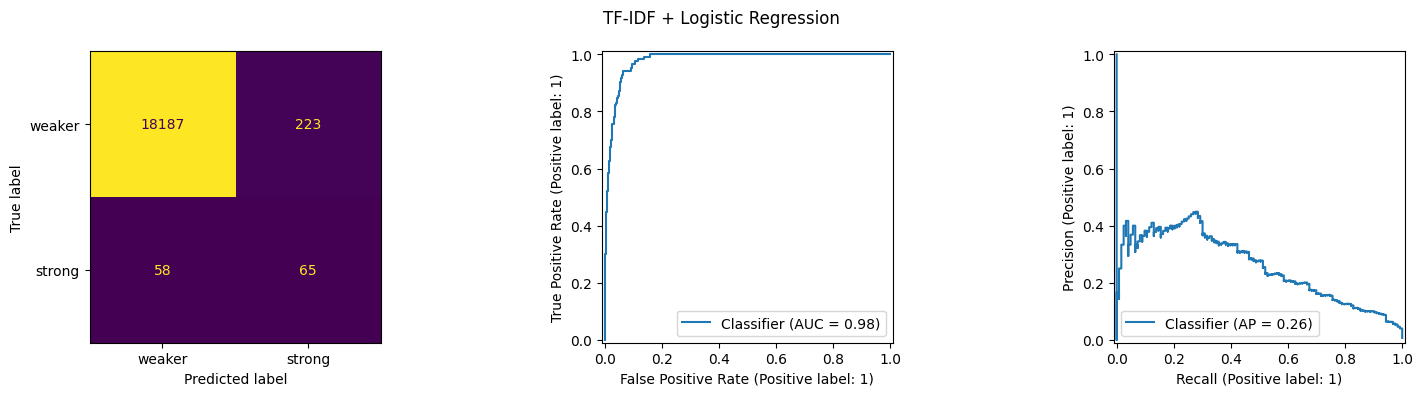

,precision,recall,f1-score,support
weaker,0.996576,0.996143,0.996360,18410.00000
strong,0.458015,0.487805,0.472441,123.00000
accuracy,0.992770,0.992770,0.992770,0.99277
macro avg,0.727296,0.741974,0.734400,18533.00000
weighted avg,0.993002,0.992770,0.992883,18533.00000


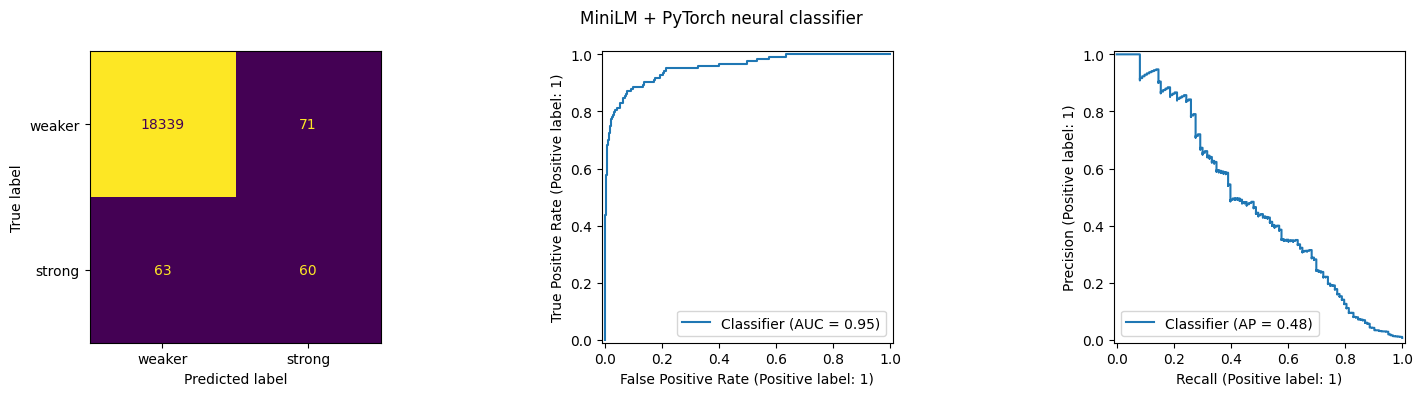

,accuracy,precision,recall,f1,roc_auc,pr_auc,average_precision
baseline,0.984838,0.225694,0.528455,0.316302,0.978586,0.251895,0.256552
pytorch,0.992770,0.458015,0.487805,0.472441,0.954105,0.478963,0.480449


,metric,goal,actual,met
0,accuracy,0.92,0.992770,True
1,precision,0.94,0.458015,False
2,recall,0.91,0.487805,False
3,f1,0.96,0.472441,False


In [19]:
def evaluate(p, threshold, name):
    pred=(p>=threshold).astype(int); truth=y['test']
    report=classification_report(truth,pred,labels=[0,1],target_names=['weaker','strong'],output_dict=True,zero_division=0)
    display(pd.DataFrame(report).T)
    precision,recall,_=precision_recall_curve(truth,p)
    row=dict(accuracy=accuracy_score(truth,pred),precision=precision_score(truth,pred,zero_division=0),recall=recall_score(truth,pred),f1=f1_score(truth,pred),roc_auc=roc_auc_score(truth,p),pr_auc=auc(recall,precision),average_precision=average_precision_score(truth,p))
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    ConfusionMatrixDisplay.from_predictions(truth,pred,display_labels=['weaker','strong'],ax=axes[0],colorbar=False)
    RocCurveDisplay.from_predictions(truth,p,ax=axes[1]); PrecisionRecallDisplay.from_predictions(truth,p,ax=axes[2])
    fig.suptitle(name); plt.tight_layout(); plt.show()
    return {'metrics':row,'classification_report':report,'threshold':threshold}
if globals().get('TEST_EVALUATED',False): raise RuntimeError('Test already evaluated. Use recorded results; do not retune against test.')
part = parts['test']
X['test'] = features.build(part.resume_text.tolist(), part.job_description.tolist())
r = tfidf.transform(part.r)
j = tfidf.transform(part.j)
B['test'] = hstack([r, j, r.multiply(j)], format='csr')
results = {
    'baseline': evaluate(baseline.predict_proba(B['test'])[:, 1], baseline_threshold, 'TF-IDF + Logistic Regression'),
    'pytorch': evaluate(probabilities(classifier, scaler, X['test'], DEVICE), threshold, 'MiniLM + PyTorch neural classifier'),
}
TEST_EVALUATED=True
display(pd.DataFrame({k:v['metrics'] for k,v in results.items()}).T)
goals={'accuracy':.92,'precision':.94,'recall':.91,'f1':.96}
display(pd.DataFrame([{'metric':k,'goal':v,'actual':results['pytorch']['metrics'][k],'met':results['pytorch']['metrics'][k]>=v} for k,v in goals.items()]))


In [20]:
audit=[]
for skill in ['Python SQL Docker','Java Git MySQL','JavaScript Node.js REST API','Excel Accounting Budgeting']:
    body='Skills: '+skill+'\nExperience: 5 years delivering projects.'
    job='Required skills: '+skill
    variants={'name':('Name: Alex Morgan\n','Name: Priya Sen\n'),'pronoun':('Pronouns: he/him\n','Pronouns: she/her\n'),'age':('Age: 25\n','Age: 55\n')}
    for attribute,(a,b) in variants.items():
        for mask in [False,True]:
            matrix = features.build([a+body,b+body],[job,job],mask=mask)
            p = probabilities(classifier, scaler, matrix, DEVICE)
            audit.append(dict(attribute=attribute,masked=mask,change=100*abs(p[0]-p[1]),flip=int((p[0]>=threshold)!=(p[1]>=threshold))))
audit=pd.DataFrame(audit)
fairness=audit.groupby(['attribute','masked']).agg(mean_change=('change','mean'),p95_change=('change',lambda x:np.percentile(x,95)),max_change=('change','max'),flip_rate=('flip','mean'),pairs=('change','size')).reset_index()
display(fairness)
print('Changes are score points on a 0–100 scale. Interpret only within these synthetic pairs.')


Encoding unique texts:   0%|          | 0/3 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/1 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/1 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/3 [00:00<?, ?it/s]

... (12 outputs left out)

Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/1 [00:00<?, ?it/s]

,attribute,masked,mean_change,p95_change,max_change,flip_rate,pairs
0,age,False,0.423402,1.432312,1.683408,0.0,4
1,age,True,0.000000,0.000000,0.000000,0.0,4
2,name,False,0.459148,1.504104,1.755322,0.0,4
3,name,True,0.000000,0.000000,0.000000,0.0,4
4,pronoun,False,17.272011,45.643559,50.402271,0.0,4
5,pronoun,True,0.000000,0.000000,0.000000,0.0,4


Changes are score points on a 0–100 scale. Interpret only within these synthetic pairs.


In [21]:
from google.colab import output as colab_output
colab_output.enable_custom_widget_manager()
import ipywidgets as widgets
resume_box=widgets.Textarea(description='Résumé',layout=widgets.Layout(width='95%',height='180px'))
job_box=widgets.Textarea(description='Job',layout=widgets.Layout(width='95%',height='180px'))
button=widgets.Button(description='Predict',button_style='primary'); output=widgets.Output()
def on_predict(_):
    with output:
        output.clear_output()
        try:
            answer=predict(features,classifier,scaler,threshold,resume_box.value,job_box.value,DEVICE)
            display(pd.DataFrame([{'Result':k,'Value':', '.join(v) if isinstance(v,list) else v} for k,v in answer.items()]))
        except ValueError as error: print(str(error))
button.on_click(on_predict)
display(widgets.VBox([resume_box,job_box,button,output]))


In [22]:
package = ROOT / 'export'
if package.exists():
    shutil.rmtree(package)
package.mkdir()
features.encoder.save(str(package / 'encoder'))
torch.save({key: value.detach().cpu() for key, value in classifier.state_dict().items()}, package / 'classifier.pt')
joblib.dump(scaler, package / 'scaler.joblib')
(package / 'ats_core.py').write_text(MODULE)
settings = {
    'threshold': threshold, 'label_mapping': {'0': 'weaker match', '1': 'strong match'},
    'reference_labels': {'strong_positive': 1, 'medium_positive': 0, 'weak_positive': 0},
    'encoder': 'sentence-transformers/all-MiniLM-L6-v2', 'encoder_frozen': True,
    'chunk_tokens': features.chunk_tokens, 'pooling': 'token-weighted normalized chunk mean then L2',
    'feature_dimension': 770, 'feature_order': ['cosine', 'abs_difference_384', 'product_384', 'skill_coverage'],
    'network': [770, 256, 64, 1], 'dropout': [0.3, 0.2], 'mask': True, 'seed': SEED,
    'learning_rate': selected['learning_rate'], 'best_epoch': selected['best_epoch'],
    'positive_weight': positive_weight,
}
(package / 'settings.json').write_text(json.dumps(settings, indent=2))
(package / 'skills.json').write_text(json.dumps(SKILLS, indent=2))
versions = {name: importlib.metadata.version(name) for name in [
    'torch', 'sentence-transformers', 'transformers', 'scikit-learn', 'numpy', 'pandas',
    'joblib', 'tokenizers', 'huggingface-hub', 'safetensors', 'scipy', 'tqdm']}
(package / 'dependency_versions.json').write_text(json.dumps({'python': sys.version, **versions}, indent=2))
# Local CUDA wheel suffixes are recorded above. Use the public base version for installation.
(package / 'requirements.txt').write_text('\n'.join(f'{key}=={value.split("+")[0]}' for key, value in versions.items()))
checks = {'schema_and_joins': 'passed', 'candidate_and_duplicate_isolation': 'passed',
          'feature_dimensions': 'passed', 'preprocessing_examples': 'passed',
          'pytorch_training': 'completed', 'held_out_evaluation': 'completed',
          'interactive_widget': 'manual verification required'}
evaluation_record = {
    'test': results, 'validation': {'baseline': baseline_trials, 'pytorch': neural_trials},
    'training_history': training_history, 'fairness': fairness.to_dict('records'),
    'join_report': join_report, 'split_sizes': {key: len(value) for key, value in parts.items()},
    'split_class_counts': {key: {str(k): int(v) for k, v in value.target.value_counts().items()}
                           for key, value in parts.items()},
    'goals': goals, 'checks': checks,
}
(package / 'evaluation.json').write_text(json.dumps(evaluation_record, indent=2))
(package / 'predict.py').write_text("""from ats_core import Predictor
from pathlib import Path
import argparse
import json

if __name__ == '__main__':
    parser = argparse.ArgumentParser(description='Score one resume and job text pair.')
    parser.add_argument('--resume', required=True, help='UTF-8 resume text file')
    parser.add_argument('--job', required=True, help='UTF-8 job-description text file')
    args = parser.parse_args()
    model = Predictor(Path(__file__).parent)
    result = model.predict(Path(args.resume).read_text(encoding='utf-8'),
                           Path(args.job).read_text(encoding='utf-8'))
    print(json.dumps(result, indent=2))
""")
(package / 'README.md').write_text(f"""# Inclusive Resume and Job Matching
Use Python {sys.version_info.major}.{sys.version_info.minor}. Create a virtual environment and install:

    pip install -r requirements.txt
    python predict.py --resume resume.txt --job job.txt

Both inputs are UTF-8 plain-text files. From Python:

    from ats_core import Predictor
    model = Predictor('.')
    result = model.predict('Python SQL experience', 'Python and SQL required')

The local encoder supports offline inference after dependencies are installed. CPU is the default.
See settings.json for architecture, threshold, labels and feature settings.
See evaluation.json for actual training, test and audit results.
Only load a trusted package because the scaler uses joblib.
""")
(package / 'MODEL_CARD.md').write_text("""# Model card
Research prototype for Inclusive Resume and Job Matching, SDG 10.
Dataset: https://huggingface.co/datasets/nonameee12233/job-resume-matching
Encoder: https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2
Frozen pretrained MiniLM plus a PyTorch MLP trained on text pair features.
Target: strong_positive versus medium_positive/weak_positive supplied reference labels.
Only text-derived features are used. Scores, existing embeddings and IDs are excluded.
Candidate identities and normalized duplicate resumes are isolated across splits. Jobs may overlap.
Exact duplicate grouping misses revised resumes. Reference labels need independent human review.
Skill coverage assumes every detected job skill is required and can miss negation and synonyms.
Masking is heuristic and can miss proxies or remove useful text. Synthetic sensitivity tests have small support.
Audit results do not establish population fairness. No sensitive demographic identity is inferred.
The score estimates the supplied strong-match label. Class weighting can distort probability calibration.
Actual results and unmet performance targets appear in evaluation.json. Performance is not guaranteed.
Use for research and candidate feedback with human review. Review source provenance and permissions before deployment.
""")
zip_path = shutil.make_archive(str(ROOT / 'inclusive_resume_job_matching_model'), 'zip', package)
reload_folder = ROOT / 'reload_check'
if reload_folder.exists():
    shutil.rmtree(reload_folder)
shutil.unpack_archive(zip_path, reload_folder)
fresh = Predictor(reload_folder, device=DEVICE)
for resume, job in [
    ('Name: Alex Morgan\nPython SQL, 5 years experience', 'Python SQL required'),
    ('Name: Priya Sen\nJava Docker', 'Python AWS required'),
]:
    before = predict(features, classifier, scaler, threshold, resume, job, DEVICE)
    after = fresh.predict(resume, job)
    np.testing.assert_allclose(before['score'], after['score'], rtol=1e-5, atol=1e-4)
    np.testing.assert_allclose(features.build([resume], [job]),
                               fresh.features.build([resume], [job]), rtol=1e-5, atol=1e-5)
    assert before['prediction'] == after['prediction']
    assert before['matched_skills'] == after['matched_skills']
    assert before['missing_skills'] == after['missing_skills']
try:
    fresh.predict('', 'Python')
except ValueError:
    print('Reloaded empty-input check passed.')
else:
    raise AssertionError('Empty-input validation failed.')
checks['archive_reload_consistency'] = 'passed'
(package / 'evaluation.json').write_text(json.dumps(evaluation_record, indent=2))
zip_path = shutil.make_archive(str(ROOT / 'inclusive_resume_job_matching_model'), 'zip', package)
EXPORT_VERIFIED = True
print('Archive reload consistency passed. Ready to download:', zip_path)


Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Encoding unique texts:   0%|          | 0/2 [00:00<?, ?it/s]

Reloaded empty-input check passed.
Archive reload consistency passed. Ready to download: /content/inclusive_ats_pytorch/inclusive_resume_job_matching_model.zip


In [23]:
import pickle
from google.colab import files

model_bundle = {
    "model_type": "MiniLM + PyTorch MLP",
    "architecture": [770, 256, 64, 1],
    "dropout": [0.3, 0.2],
    "weights": {
        name: tensor.detach().cpu().numpy()
        for name, tensor in classifier.state_dict().items()
    },
    "scaler": scaler,
    "threshold": float(threshold),
    "label_mapping": {0: "weaker match", 1: "strong match"},
    "encoder_name": "sentence-transformers/all-MiniLM-L6-v2",
    "chunk_tokens": features.chunk_tokens,
    "skill_vocabulary": features.vocabulary
}

model_path = "/content/model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(model_bundle, file, protocol=pickle.HIGHEST_PROTOCOL)

print("Saved trained classifier to model.pkl")
files.download(model_path)

Saved trained classifier to model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>